# Avance 2: Análisis SQL y optimización con índices
**Proyecto Integrador M2 · FleetLogix · Tomás Babot**

En este avance:
1. Ejecuto **8 de las 12 queries** provistas (`2. Scripts/02_queries_analysis.sql`) e interpreto cada resultado para el negocio.
2. Mido su tiempo con `EXPLAIN ANALYZE` **antes y después** de crear 5 índices (`2. Scripts/03_optimization_indexes.sql`).

**Queries elegidas** (según la regla de la consigna):

| Nivel | Queries | Elección |
|---|---|---|
| Básicas | 1, 2, 3 | las 3 obligatorias |
| Intermedias | 4, 5 + una de 6/7/8 | **7** (consumo de combustible por ruta: costo directo de la operación) |
| Complejas | 9 + una de 10/11/12 | **10** (ranking de conductores con funciones de ventana) |

In [1]:
import os, re, json, statistics
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv('../.env')
config = dict(host=os.getenv('PGHOST', 'localhost'), dbname=os.getenv('PGDATABASE', 'fleetlogix'),
              user=os.getenv('PGUSER', os.getenv('USER')), password=os.getenv('PGPASSWORD', ''), port=5432)

engine = create_engine('postgresql+psycopg2://', connect_args=config)   # para leer con pandas
conn = psycopg2.connect(**config)                                         # para EXPLAIN y crear índices
conn.autocommit = True
cur = conn.cursor()

def consulta(sql):
    return pd.read_sql(sql, engine)

# Leer las queries del archivo .sql (cada una empieza con "-- Query N:")
texto = open('../2. Scripts/02_queries_analysis.sql', encoding='utf-8').read()
partes = re.split(r'\n-- (Query \w+):', texto)
queries = {}
for i in range(1, len(partes), 2):
    cuerpo = partes[i + 1].split('\n', 1)[1]
    cuerpo = '\n'.join(l for l in cuerpo.splitlines() if l.strip() and not l.strip().startswith('--'))
    queries[partes[i]] = cuerpo[:cuerpo.index(';')]
list(queries)

['Query 1',
 'Query 2',
 'Query 3',
 'Query 4',
 'Query 5',
 'Query 7',
 'Query 9',
 'Query 9b',
 'Query 10']

## 1. Resultados e interpretación de negocio

### Query 1: Composición de la flota
*Problema:* saber con qué vehículos cuenta la empresa.

In [2]:
consulta(queries['Query 1'])

,vehicle_type,cantidad
0,Van,69
1,Camión Grande,60
2,Camión Mediano,51
3,Motocicleta,20


**Interpretación:** la flota es de 200 vehículos y está dominada por **Vans (69)** y **camiones grandes (60)**.
Las motos son solo 20: sirven para paquetes chicos de última milla. La empresa está preparada sobre todo
para carga media y pesada entre ciudades.

### Query 2: Licencias por vencer
*Problema:* evitar que un conductor maneje con la licencia vencida (multas, problemas legales y de seguro).

In [3]:
consulta(queries['Query 2'])

,first_name,last_name,license_number,license_expiry,status
0,Milena,Galeano,2753617371,2026-11-19,active
1,Rocío,Valencia,8118240999,2026-11-24,active
2,Johana,Muñoz,5594799319,2026-11-26,active
3,Diego,Castro,7105574449,2026-11-27,active
4,María,Caicedo,6265016831,2026-11-28,active
5,Karen,Vanegas,5344083406,2026-11-28,active
6,Nelly,Yepes,7430757004,2026-12-02,active
7,Alexander,Rodríguez,5877639950,2026-12-02,active
8,Sebastián,Loaiza,4746123831,2026-12-03,active
9,Esperanza,Rendón,5696548897,2026-12-04,active


**Interpretación:** hay alrededor de una docena de conductores con la licencia venciendo en los próximos 30 días,
casi todos **activos**. Recursos Humanos debería avisarles hoy para que la renueven; si no, habría que sacarlos de la
programación de viajes. Conviene correr esta consulta todos los días como alerta automática.

### Query 3: Viajes por estado
*Problema:* monitorear la operación en curso.

In [4]:
consulta(queries['Query 3'])

,status,total_viajes
0,completed,99999
1,in_progress,1


**Interpretación:** casi el 100% de los viajes históricos están **completados**; solo quedan unos pocos **en curso**
(los que salieron en las últimas horas). No hay viajes "trabados" en curso por días, lo que indica que el registro de
llegadas funciona bien.

### Query 4: Demanda por ciudad (últimos 60 días)
*Problema:* planificar vehículos y personal según la demanda de cada ciudad.

In [5]:
q4 = consulta(queries['Query 4'])
q4['%_entregas'] = (100 * q4['total_entregas'] / q4['total_entregas'].sum()).round(1)
q4

,destination_city,total_viajes,total_entregas,peso_total_kg,%_entregas
0,Bogotá,2550,10106,5021331.64,26.3
1,Medellín,2087,8334,3964942.24,21.7
2,Cali,1870,7553,3703033.43,19.7
3,Barranquilla,1645,6537,3045394.01,17.0
4,Cartagena,1460,5854,2996545.50,15.3


**Interpretación:** **Bogotá** es el principal destino (~26% de las entregas), seguida por Medellín y Cali.
Barranquilla y Cartagena reciben menos. La flota y los turnos de reparto deberían asignarse en esa proporción;
en Bogotá conviene tener el mayor centro de distribución.

### Query 5: Carga de trabajo por conductor
*Problema:* detectar conductores sobrecargados o con poca asignación.

In [6]:
q5 = consulta(queries['Query 5'])
display(q5.head(10))
q5['viajes_totales'].describe().round(1)

,driver_id,nombre_completo,license_expiry,viajes_totales,viajes_completados
0,34,Jorge Gamboa,2029-05-09,383,383
1,167,Antonio Alvarado,2028-10-03,382,382
2,107,Josefa Parra,2029-09-23,378,378
3,55,Esperanza Palacio,2029-10-25,377,377
4,22,Alex Acosta,2029-05-05,376,376
5,299,Jorge Aguirre,2028-09-14,376,376
6,4,Alba Melo,2029-05-14,375,375
7,343,Ignacio García,2029-09-04,375,375
8,239,Tatiana González,2029-01-30,375,375
9,320,Duván Melo,2028-04-11,373,373


count    373.0
mean     268.1
std      109.0
min        2.0
25%      190.0
50%      330.0
75%      347.0
max      383.0
Name: viajes_totales, dtype: float64

**Interpretación:** los 373 conductores activos hicieron en promedio ~268 viajes en 2 años (la mitad, más de 330),
pero la diferencia es grande: los más cargados llegan a 383 viajes y algunos tienen muy pocos. Los de pocos viajes son
**contratados hace poco** (el script solo asigna viajes posteriores a la fecha de contratación). Ninguno está sobrecargado:
el script de generación no le da un viaje a un conductor que no descansó 8 horas desde el anterior (ver Avance 1).
Igual conviene revisar la asignación para repartir mejor el trabajo entre los más nuevos.

### Query 7: Rutas con mayor consumo de combustible por km
*Problema:* encontrar rutas ineficientes.

In [7]:
consulta(queries['Query 7'])

,route_code,ruta,distance_km,viajes_realizados,promedio_combustible_litros,litros_por_100km,combustible_total
0,R047,Cartagena -> Cali,1131.90,1609,308.13,27.22,495780.22
1,R031,Cali -> Cartagena,1082.95,1598,293.22,27.08,468573.24
2,R042,Cartagena -> Bogotá,1059.22,1785,286.65,27.06,511671.74
3,R011,Bogotá -> Cartagena,1026.98,1778,277.82,27.05,493971.34
4,R010,Bogotá -> Cartagena,1030.83,1751,278.51,27.02,487674.48
5,R043,Cartagena -> Bogotá,1068.17,1837,288.43,27.00,529849.24
6,R012,Bogotá -> Cartagena,1018.74,1778,274.80,26.97,488597.67
7,R048,Cartagena -> Cali,1090.91,1586,293.91,26.94,466134.13
8,R044,Cartagena -> Bogotá,1095.30,1835,294.93,26.93,541190.69
9,R032,Cali -> Cartagena,1131.55,1594,303.68,26.84,484066.63


**Interpretación:** las rutas que más gastan por kilómetro son las largas a la costa (**~27 litros cada 100 km**), porque
casi todos esos viajes los hacen camiones (3 de cada 4 viajes de más de 800 km se reservan para camiones y las motos no
salen del corredor Barranquilla - Cartagena). En las rutas cortas y medias el promedio baja porque también circulan vans y motos,
que consumen mucho menos. Las rutas que más combustible **total** consumen son Bogotá - Cartagena y Cartagena - Cali:
son las primeras a optimizar (carga completa, mejores horarios, vehículo adecuado).

### Query 9: Costo de mantenimiento por km
*Problema:* evaluar el costo-beneficio de cada tipo de vehículo.

La query original une `trips` y `maintenance` **al mismo tiempo** con el vehículo. Como un vehículo tiene muchos viajes
y muchos mantenimientos, cada viaje se repite una vez por cada mantenimiento (**multiplicación de filas o fan-out**).
Resultado: los kilómetros y los costos salen inflados. Comparo la versión original con la corregida (9b), que primero
resume cada tabla por vehículo y después las une:

In [8]:
q9 = consulta(queries['Query 9'])
q9b = consulta(queries['Query 9b'])
display(q9, q9b)

km_reales = consulta("SELECT SUM(r.distance_km) AS km FROM trips t JOIN routes r ON t.route_id = r.route_id WHERE t.status = 'completed'")
costo_real = consulta('SELECT SUM(cost) AS costo FROM maintenance')
print(f"Km reales recorridos: {km_reales['km'][0]:,.0f}  | Km según query 9 original: {q9['kilometros_totales'].sum():,.0f}")
print(f"Costo real de mantenimiento: {costo_real['costo'][0]:,.0f}  | Costo según query 9 original: {q9['costo_total_mantenimiento'].sum():,.0f}")

,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,14,2563.0,3.310762e+06,3.621600e+09,1093.89,2.510124e+07
1,Camión Grande,52,31841.0,7.219653e+08,7.000053e+11,969.58,3.604945e+08
2,Camión Mediano,46,28354.0,6.252200e+08,4.976138e+11,795.90,2.964381e+08
3,Van,61,36114.0,6.392757e+08,4.717669e+11,737.97,2.116391e+08


,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,14,2563.0,321226.59,1.831316e+07,57.01,136665.39
1,Camión Grande,52,31841.0,19520878.34,9.500628e+08,48.67,588274.17
2,Camión Mediano,46,28354.0,17408544.27,6.931223e+08,39.82,480667.37
3,Van,61,36114.0,17755640.86,6.497089e+08,36.59,359153.61


Km reales recorridos: 55,659,910  | Km según query 9 original: 1,989,771,853
Costo real de mantenimiento: 2,311,207,183  | Costo según query 9 original: 1,673,007,649,970


**Interpretación:** la versión original multiplica los kilómetros ~36 veces y los costos más de 700 veces, y por eso
da un costo de ~840 COP por km, que **no es real**. En la versión corregida el costo coincide exacto con la base; los kilómetros
dan 1% menos porque quedan afuera los 3 vehículos que nunca tuvieron mantenimiento (653.620 km), que no tienen costo para dividir.
La 9b muestra un costo de mantenimiento de **~37 a 57 COP por km**: el camión grande cuesta más que la van y el mediano
(sus repuestos y servicios son más caros), y la moto es la más cara por km porque recorre pocos kilómetros (solo hace el
corredor corto) aunque cada servicio sea barato.
**Lección:** antes de usar un resultado para decidir, hay que verificar que los totales "cierren" contra la fuente.

### Query 10: Ranking de conductores (funciones de ventana)
*Problema:* elegir a los mejores conductores de los últimos 3 meses para incentivos.

In [9]:
consulta(queries['Query 10'])

,nombre,viajes,entregas,consumo_100km,puntualidad_pct,rank_puntualidad,rank_eficiencia,rank_productividad,score_promedio
0,Juan Polo,47,187,21.19,51.87,19,73,49,47.00
1,Alejandra Palacios,47,191,19.95,47.12,100,18,37,51.67
2,Rocío Valencia,47,183,21.35,53.01,12,80,68,53.33
3,Alberto Benítez,53,212,21.55,47.64,87,90,6,61.00
4,Nelly Yepes,46,192,19.93,44.79,170,17,35,74.00
5,Liliana Benavides,44,179,22.01,52.51,16,128,81,75.00
6,Alex Acosta,47,194,22.34,49.48,51,147,29,75.67
7,Steven García,47,184,22.07,50.00,38,133,62,77.67
8,Marta López,48,193,22.01,48.19,77,127,31,78.33
9,David Fernández,46,185,21.20,47.03,103,74,58,78.33


**Interpretación:** `RANK() OVER (...)` ordena a todos los conductores en tres rankings (puntualidad, consumo y cantidad de
entregas) y el `score_promedio` combina los tres: **menor score = mejor conductor**. Los primeros puestos son conductores
equilibrados en las tres métricas, no necesariamente los mejores en una sola. Ojo: esta query mide puntualidad como
"entregado antes o justo a la hora programada" (sin los 30 minutos de tolerancia), por eso los porcentajes rondan el 50%.

## 2. Optimización con índices

**Método de medición:**
- `EXPLAIN (ANALYZE, FORMAT JSON)` ejecuta la query de verdad y devuelve el **Execution Time** en milisegundos.
- Cada query se corre 7 veces; se descarta la primera (calienta la caché) y se toma la **mediana** de las otras 6.
- Primero se borran los 5 índices (estado "sin índices"), se mide, se corre `03_optimization_indexes.sql` y se vuelve a medir.

In [10]:
def medir(sql, veces=7):
    tiempos = []
    for _ in range(veces):
        cur.execute('EXPLAIN (ANALYZE, FORMAT JSON) ' + sql)
        tiempos.append(cur.fetchone()[0][0]['Execution Time'])
    return round(statistics.median(tiempos[1:]), 2)

def plan(sql):
    cur.execute('EXPLAIN ANALYZE ' + sql)
    return '\n'.join(fila[0] for fila in cur.fetchall())

INDICES = ['idx_deliveries_trip_id', 'idx_maintenance_vehicle_cost', 'idx_trips_vehicle_completed',
           'idx_trips_status', 'idx_drivers_license_expiry']

### 2.1 Medición ANTES (sin los índices nuevos)

In [11]:
cur.execute('RESET random_page_cost')
cur.execute('DROP INDEX IF EXISTS ' + ', '.join(INDICES))
cur.execute('ANALYZE')
antes = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_antes = plan(queries['Query 4'])
plan_q9_antes = plan(queries['Query 9'])
antes

{'Query 1': 0.04,
 'Query 2': 0.05,
 'Query 3': 13.91,
 'Query 4': 74.82,
 'Query 5': 30.58,
 'Query 7': 28.44,
 'Query 9': 5141.49,
 'Query 9b': 32.55,
 'Query 10': 111.63}

### 2.2 Crear los índices (`03_optimization_indexes.sql`)

In [12]:
script = open('../2. Scripts/03_optimization_indexes.sql', encoding='utf-8').read()
cur.execute(script)                       # crea los 5 índices, corre ANALYZE y lista los índices
pd.DataFrame(cur.fetchall(), columns=['tabla', 'indice', 'tamano', 'definicion'])

,tabla,indice,tamano,definicion
0,deliveries,idx_deliveries_status,2552 kB,CREATE INDEX idx_deliveries_status ON public.d...
1,deliveries,idx_deliveries_trip_id,19 MB,CREATE INDEX idx_deliveries_trip_id ON public....
2,drivers,idx_drivers_license_expiry,32 kB,CREATE INDEX idx_drivers_license_expiry ON pub...
3,maintenance,idx_maintenance_vehicle_cost,216 kB,CREATE INDEX idx_maintenance_vehicle_cost ON p...
4,trips,idx_trips_departure,2176 kB,CREATE INDEX idx_trips_departure ON public.tri...
5,trips,idx_trips_status,704 kB,CREATE INDEX idx_trips_status ON public.trips ...
6,trips,idx_trips_vehicle_completed,3104 kB,CREATE INDEX idx_trips_vehicle_completed ON pu...
7,vehicles,idx_vehicles_status,16 kB,CREATE INDEX idx_vehicles_status ON public.veh...


### 2.3 Medición DESPUÉS

In [13]:
despues = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_despues = plan(queries['Query 4'])
plan_q9_despues = plan(queries['Query 9'])

# Ajuste opcional para disco SSD (solo en esta sesión, no cambia el servidor)
cur.execute('SET random_page_cost = 1.1')
despues_ssd = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_ssd = plan(queries['Query 4'])
cur.execute('RESET random_page_cost')

In [14]:
tabla = pd.DataFrame({'sin_indices_ms': antes, 'con_indices_ms': despues, 'indices_+_ssd_ms': despues_ssd})
tabla['mejora_indices_%'] = (100 * (1 - tabla['con_indices_ms'] / tabla['sin_indices_ms'])).round(1)
tabla['mejora_indices_+_ssd_%'] = (100 * (1 - tabla['indices_+_ssd_ms'] / tabla['sin_indices_ms'])).round(1)

# La 9b es la versión corregida de la 9: se muestra aparte para no mezclarla en el total de las 8 queries
ocho = tabla.drop(index='Query 9b')
total = ocho[['sin_indices_ms', 'con_indices_ms', 'indices_+_ssd_ms']].sum()
ocho.loc['TOTAL 8 queries'] = list(total) + [round(100 * (1 - total.iloc[1] / total.iloc[0]), 1),
                                             round(100 * (1 - total.iloc[2] / total.iloc[0]), 1)]
ocho

,sin_indices_ms,con_indices_ms,indices_+_ssd_ms,mejora_indices_%,mejora_indices_+_ssd_%
Query 1,0.04,0.04,0.04,0.0,0.0
Query 2,0.05,0.01,0.01,80.0,80.0
Query 3,13.91,9.13,9.21,34.4,33.8
Query 4,74.82,77.17,45.23,-3.1,39.5
Query 5,30.58,30.73,30.51,-0.5,0.2
Query 7,28.44,28.80,28.62,-1.3,-0.6
Query 9,5141.49,1114.53,1062.68,78.3,79.3
Query 10,111.63,111.78,69.80,-0.1,37.5
TOTAL 8 queries,5400.96,1372.19,1246.10,74.6,76.9


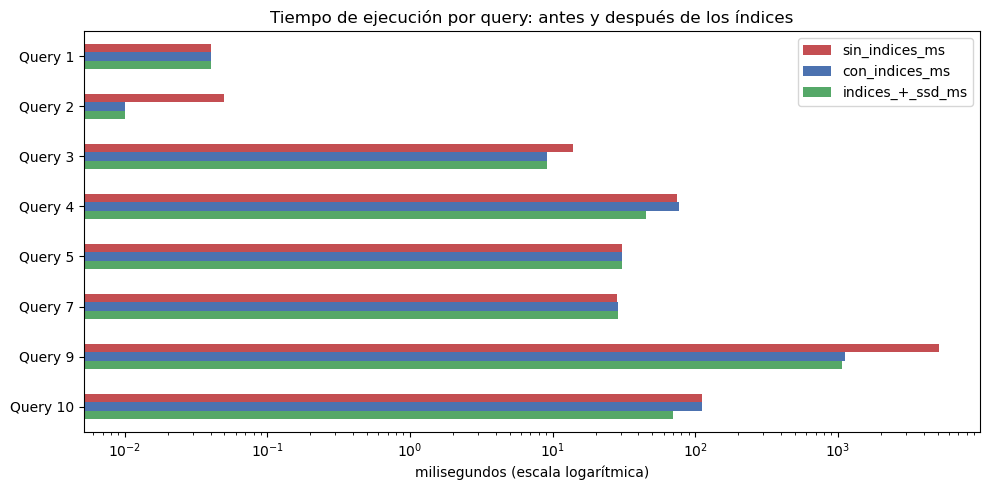

In [15]:
datos = ocho.drop(index='TOTAL 8 queries')[['sin_indices_ms', 'con_indices_ms', 'indices_+_ssd_ms']]
ax = datos.plot(kind='barh', figsize=(10, 5), color=['#C44E52', '#4C72B0', '#55A868'], logx=True)
ax.set_xlabel('milisegundos (escala logarítmica)')
ax.set_title('Tiempo de ejecución por query: antes y después de los índices')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

### 2.4 Reescritura de la Query 9: corregir el fan-out también la hace más rápida

In [16]:
comparacion_9 = pd.DataFrame({
    'version': ['9 original (sin índices)', '9 original (con índices)', '9b corregida (con índices)'],
    'ms': [antes['Query 9'], despues['Query 9'], despues['Query 9b']]})
comparacion_9['veces_mas_rapida_que_original'] = (antes['Query 9'] / comparacion_9['ms']).round(1)
comparacion_9

,version,ms,veces_mas_rapida_que_original
0,9 original (sin índices),5141.49,1.0
1,9 original (con índices),1114.53,4.6
2,9b corregida (con índices),32.74,157.0


### 2.5 ¿Qué cambió en los planes de ejecución?
Las líneas clave del plan: **Seq Scan** = lee la tabla completa; **Index Scan / Index Only Scan** = va directo a las filas que necesita.

In [17]:
def lineas_clave(texto):
    claves = ('Scan', 'Join', 'Nested Loop', 'Execution Time', 'Rows Removed')
    return '\n'.join(l for l in texto.splitlines() if any(c in l for c in claves))

print('===== QUERY 4 - ANTES =====');  print(lineas_clave(plan_q4_antes))
print('\n===== QUERY 4 - CON ÍNDICES + SSD =====');  print(lineas_clave(plan_q4_ssd))

===== QUERY 4 - ANTES =====
              ->  Hash Join  (cost=505.45..13007.99 rows=38804 width=23) (actual time=23.945..41.592 rows=38384.00 loops=1)
                    ->  Hash Join  (cost=503.33..12895.37 rows=38804 width=18) (actual time=23.929..36.854 rows=38384.00 loops=1)
                          ->  Seq Scan on deliveries d  (cost=0.00..11342.00 rows=400000 width=14) (actual time=0.003..13.197 rows=400000.00 loops=1)
                                ->  Index Scan using idx_trips_departure on trips t  (cost=0.30..382.06 rows=9701 width=8) (actual time=0.008..0.838 rows=9612.00 loops=1)
                          ->  Seq Scan on routes r  (cost=0.00..1.50 rows=50 width=13) (actual time=0.005..0.009 rows=50.00 loops=1)
Execution Time: 74.132 ms

===== QUERY 4 - CON ÍNDICES + SSD =====
              ->  Nested Loop  (cost=2.84..8128.07 rows=38560 width=23) (actual time=0.028..13.166 rows=38384.00 loops=1)
                    ->  Hash Join  (cost=2.42..328.37 rows=9640 width=13) (

In [18]:
print('===== QUERY 9 - ANTES =====');  print(lineas_clave(plan_q9_antes))
print('\n===== QUERY 9 - DESPUÉS =====');  print(lineas_clave(plan_q9_despues))

===== QUERY 9 - ANTES =====
              ->  Subquery Scan on vehicle_metrics  (cost=450640.99..488145.21 rows=22 width=95) (actual time=3983.710..5228.780 rows=173.00 loops=1)
                          Rows Removed by Filter: 3
                                ->  Hash Join  (cost=220.53..31161.28 rows=2500000 width=45) (actual time=1.443..340.677 rows=3523133.00 loops=1)
                                      ->  Hash Left Join  (cost=2.12..2567.88 rows=100000 width=15) (actual time=0.016..28.635 rows=99999.00 loops=1)
                                            ->  Seq Scan on trips t  (cost=0.00..2281.00 rows=100000 width=12) (actual time=0.005..13.868 rows=99999.00 loops=1)
                                                  Rows Removed by Filter: 1
                                                  ->  Seq Scan on routes r  (cost=0.00..1.50 rows=50 width=11) (actual time=0.002..0.005 rows=50.00 loops=1)
                                            ->  Hash Right Join  (cost=6.50..155

In [19]:
uso = consulta('''
    SELECT relname AS tabla, indexrelname AS indice, idx_scan AS veces_usado,
           pg_size_pretty(pg_relation_size(indexrelid)) AS tamano
    FROM pg_stat_user_indexes
    WHERE indexrelname IN ('idx_deliveries_trip_id', 'idx_maintenance_vehicle_cost',
                           'idx_trips_vehicle_completed', 'idx_trips_status', 'idx_drivers_license_expiry')
    ORDER BY indice
''')
uso

,tabla,indice,veces_usado,tamano
0,deliveries,idx_deliveries_trip_id,67328,19 MB
1,drivers,idx_drivers_license_expiry,14,32 kB
2,maintenance,idx_maintenance_vehicle_cost,2670,216 kB
3,trips,idx_trips_status,14,704 kB
4,trips,idx_trips_vehicle_completed,7,3104 kB


In [20]:
# Guardar los resultados para la documentación
os.makedirs('../3. Documentación/img', exist_ok=True)
ocho.to_csv('../3. Documentación/tiempos_indices.csv')
ax = datos.plot(kind='barh', figsize=(10, 5), color=['#C44E52', '#4C72B0', '#55A868'], logx=True)
ax.set_xlabel('milisegundos (escala logarítmica)'); ax.set_title('Tiempo por query: antes y después de los índices')
ax.invert_yaxis(); plt.tight_layout(); plt.savefig('../3. Documentación/img/tiempos_indices.png', dpi=150); plt.close()
print('Guardado')

Guardado


## 3. Conclusiones del Avance 2

- Las 8 queries responden preguntas concretas del negocio: composición de flota, alertas de licencias, demanda por ciudad,
  carga por conductor, consumo por ruta, costo de mantenimiento y ranking para incentivos.
- Encontré y corregí un **error de lógica en la Query 9** (fan-out): la versión original inflaba kilómetros y costos.
  La versión corregida (9b) da números que cierran con la base y además es mucho más rápida.
- Con los **5 índices** el tiempo total de las 8 queries baja un **74,6%** (de 5.401 a 1.372 ms, ver la fila TOTAL de la tabla).
  La mayor ganancia está en la Query 9, que pasa a resolver los mantenimientos por vehículo directamente desde el índice.
- Con el ajuste para SSD (`random_page_cost = 1.1`, solo de sesión) PostgreSQL usa además el índice de entregas por viaje
  en las queries 4 y 10, que también bajan.
- **Las queries 5 y 7 no mejoran**, y es lo esperado: recorren los 100.000 viajes para agrupar, y para leer toda una tabla
  la lectura secuencial es la forma más rápida. Un índice solo ayuda cuando se necesita una parte chica de los datos.
- Los índices tienen costo (espacio y escrituras más lentas), por eso se crearon solo los que tienen una query que los usa.